# Task 2.3: Reading the qubit through the buffer

**Method.** Switch on a small drive on the memory and watch the light leaking out of the buffer. Its sign tells you which valley the qubit is in.

In [1]:
import sys, json, glob
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'research/s2').is_dir())
S2 = ROOT / 'results/s2'
load = lambda pat: [json.loads(Path(f).read_text()) for f in sorted(glob.glob(str(S2 / pat)))]
show = lambda name, w=750: display(Image(filename=str(ROOT / 'figures/s2' / f'{name}.png'), width=w))
sys.path.insert(0, str(ROOT))
from research.s2.common import KAPPA_A
nominal = lambda d: d['eps_z_over_g2'] == 0 and d['n_th'] == 0 and d['kappa_a'] == KAPPA_A and abs(d['kappa_b'] - 16.3363) < 1e-3

def largest(rows):
    best = {}
    for d in rows:
        k = round(d['alpha'], 2)
        if k not in best or d['na'] * d['nb'] > best[k]['na'] * best[k]['nb']:
            best[k] = d
    return best

In [2]:
d = load('readout_a2.10_36x10_T4.json')[0]
pd.DataFrame([{'drive (× g2)': r['eps_over_g2'], 'ring (MHz)': round(r['ring'].get('f_MHz', float('nan')), 2),
               'quality factor': round(r['ring'].get('Q', float('nan')), 2), 'settles in (µs)': round(r['settle_1pct_us'], 2)}
              for r in d['runs'] if r['eps_over_g2'] <= 0.5])

,drive (× g2),ring (MHz),quality factor,settles in (µs)
0,0.1,3.21,2.05,0.97
1,0.5,3.21,2.05,0.86


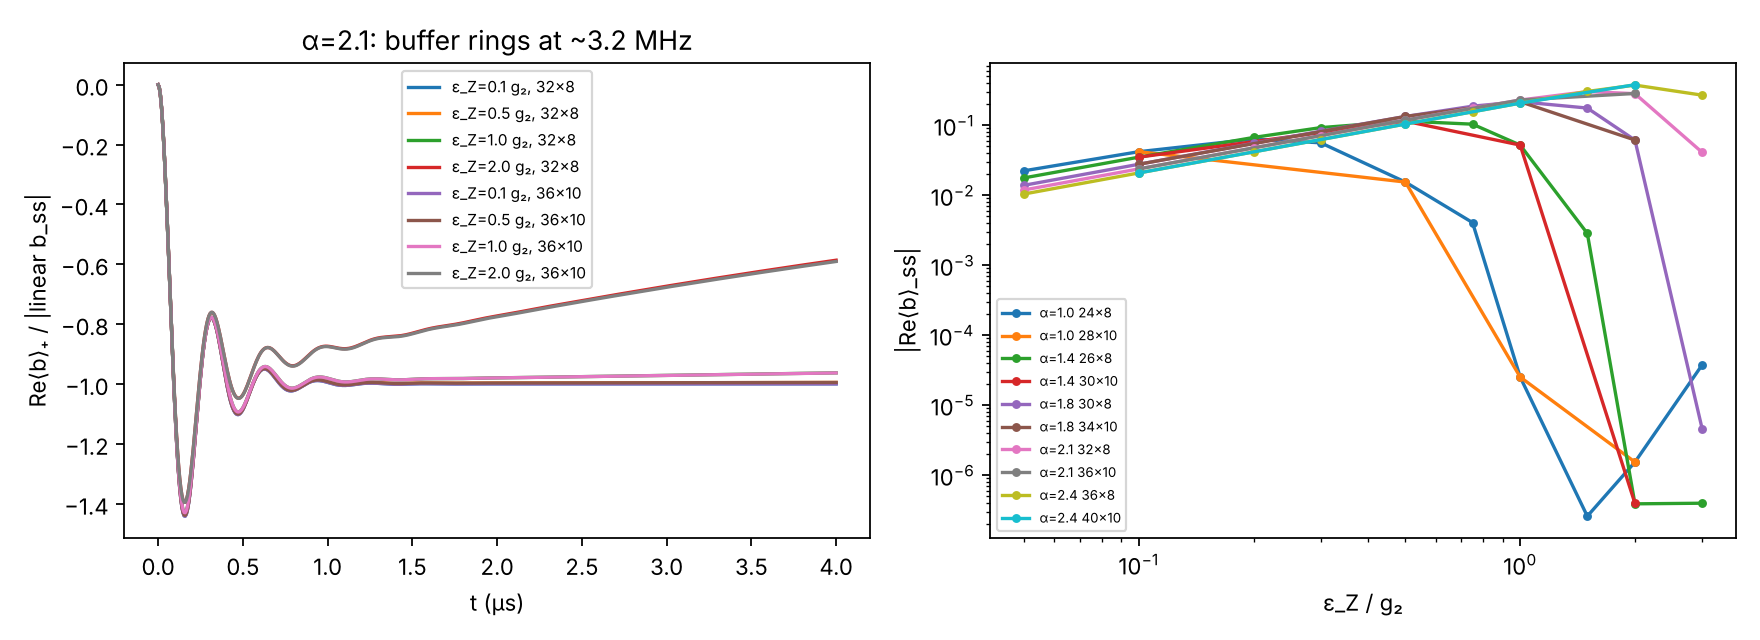

In [3]:
show('readout', 900)

**Result.** The signal matches the linear prediction to 1%, but it **rings at 3.2 MHz** and needs about **1 µs** to settle. Memory and buffer act like two coupled springs; this is the same ringing as the overshoot in Task 1.1.